This file is as same as the simple agent , but in this we are adding the structured output and the streaming adding the additional features, the rest will remain smae.

In [19]:
# imports and configrations

In [39]:
from langsmith import Client
from pathlib import Path
from dotenv import load_dotenv
import langsmith as ls
import os

In [40]:
from langchain_openai import ChatOpenAI
from langchain_core.messages import HumanMessage, SystemMessage, BaseMessage, AIMessage, ToolMessage
from langchain.tools import tool
from langgraph.graph import StateGraph, START, END, add_messages
from langgraph.prebuilt import ToolNode, tools_condition

from typing import TypedDict, Literal, Annotated
from typing_extensions import NotRequired

from pydantic import BaseModel, Field
from rich import print
import sys
import time

In [41]:
env_path = Path.cwd().parent.parent / ".env"
load_dotenv(env_path)
openai_api_key = os.getenv("OPENAI_API_KEY")
langsmith_api_key = os.getenv("LANGSMITH_API_KEY")


In [42]:
os.environ["LANGSMITH_PROJECT"] = "simple-agent"
os.environ["LANGCHAIN_PROJECT"] = "simple-agent"
os.environ["LANGCHAIN_TRACING_V2"] = "true" 

In [43]:
# business logic

In [44]:
model = ChatOpenAI(
    model="gpt-4.1-mini",
    api_key=openai_api_key,
    temperature=0
)

In [45]:
class StructuredOutputForToolCall(BaseModel):
    question: str = Field(
        ...,
        description="The original user question or calculation request"
    )
    num: float = Field(
        ...,
        description="Contains the final output as the numerical value from the tool call"
    )

    @property
    def formatted_response(self) -> str:
        return f"For your question '{self.question}' the output is {self.num}"

In [46]:
# defining tools 

In [47]:
@tool
def add(num1:float, num2:float) -> float:
    """This tool is used to add two numbers"""
    return num1 + num2


@tool
def subtract(num1:float, num2:float) -> float:
    """This tool is used to subtract two numbers"""
    return num1 - num2

@tool
def multiply(num1:float, num2:float) -> float:
    """This tool is used to multiply two numbers"""
    return num1 * num2

@tool
def divide(num1:float, num2:float) -> float:
    """This tool is used to divide two numbers"""
    try:
        return num1 / num2
    except ZeroDivisionError:
        print("Error: Cannot divide by zero")
        return None

In [48]:
class State(BaseModel):
    messages: Annotated[list[BaseMessage], add_messages] = Field(default_factory=list)
    structured_response: StructuredOutputForToolCall | None = None

In [49]:
# binding the model with the tools and structured output
tools = [add, subtract, multiply, divide]
model_with_tools = model.bind_tools(tools)
structured_model = model.with_structured_output(StructuredOutputForToolCall)

In [50]:
def agent_node(state: State):
    # Since state is a Pydantic model, access attributes via dot notation
    messages = state.messages

    # Check if a tool was just executed (last message is a ToolMessage)
    if isinstance(messages[-1], ToolMessage):
        structured_res = structured_model.invoke(messages)
        content = f"For your question '{structured_res.question}' the output is {structured_res.num}"
        return {
            "messages": [AIMessage(content=content)],
            "structured_response": structured_res
        }

    # General conversation or model deciding whether to invoke a tool
    response = model_with_tools.invoke(messages)
    return {
        "messages": [response],
        "structured_response": None
    }

In [51]:
def should_continue(state: State):
    messages = state.messages
    last_message = messages[-1]

    if getattr(last_message, "tool_calls", None):
        return "tools"

    return "end" 

In [52]:
from langgraph.prebuilt import ToolNode

tools_node = ToolNode(tools)

In [53]:
# Build the graph

In [54]:
# defining the graph
graph = StateGraph(State)

# defining the nodes
graph.add_node("agent", agent_node)
graph.add_node("tools", tools_node)

# defining the edges
graph.add_edge(START, "agent")

graph.add_conditional_edges(
    "agent",
    should_continue,
    {
        "tools": "tools",
        "end": END
    }
)

# After executing tools, return to the agent
graph.add_edge("tools", "agent")

workflow = graph.compile()

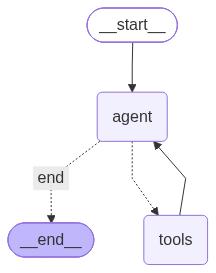

In [55]:
workflow

In [56]:
# making the instance of the state class
state = State()

# defining the configuration for the workflow
config = {
    "configurable": {
        "thread_id": "user_123"
    }
}

In [57]:
def stream_response(text: str, delay: float = 0.012):
    """Streams text character-by-character to stdout for real-time response delivery."""
    for char in text:
        sys.stdout.write(char)
        sys.stdout.flush()
        time.sleep(delay)
    print()

while True:
    user_query = input("Enter your query: ")

    # Check if the user wants to exit the program
    if user_query.lower() == "exit":
        print("Exiting the program.")
        break

    print(f"\nUser Query: {user_query}")

    human_message = HumanMessage(content=user_query)
    state.messages.append(human_message)

    # Stream the workflow updates in real-time
    for event in workflow.stream(state, config=config, stream_mode="updates"):
        for node_name, node_output in event.items():
            # Keep state messages synchronized with node updates
            if "messages" in node_output:
                state.messages.extend(node_output["messages"])
            if "structured_response" in node_output and node_output["structured_response"] is not None:
                state.structured_response = node_output["structured_response"]

            # Stream progress live for tool calls and all responses
            if node_name == "agent":
                latest_msg = node_output["messages"][-1]
                if getattr(latest_msg, "tool_calls", None):
                    for tc in latest_msg.tool_calls:
                        print(f"⚡ [Streaming] Invoking tool '{tc['name']}' with args: {tc['args']}")
                else:
                    # Stream the response content live in real-time
                    sys.stdout.write("🤖 AI Response: ")
                    sys.stdout.flush()
                    stream_response(latest_msg.content)
            elif node_name == "tools":
                print(f"🔧 [Streaming] Tool execution result: {node_output['messages'][-1].content}")

    # If a tool call occurred, display the structured schema object
    if state.structured_response is not None:
        print(f"📦 Structured Output Schema: {state.structured_response}")
        # Reset for subsequent turns
        state.structured_response = None

    print()

User Query: hey , how is going ?

🤖 AI Response: Hello! I'm doing great, thank you for asking. How can I assist you today?

User Query: how are you ?

🤖 AI Response: I'm just a computer program, so I don't have feelings, but I'm here and ready to help you! What can I do for you today?

User Query: Ok so great.

🤖 AI Response: I'm glad to hear that! If there's anything you'd like to talk about or need help with, just let me know.

... (16 outputs left out)

📦 Structured Output Schema: question='What is 369 multiplied by 3?' num=1107.0

User Query: ok thankyou.

🤖 AI Response: You're welcome! If you have any more questions or want to chat about anything else, feel free to ask. Have a great day!

Exiting the program.